# Mobile Price Classification

Individual machine learning coursework project, revised for a reproducible portfolio. Predict four price categories from phone specifications using KNN and a Decision Tree. The public evaluation below fixes preprocessing leakage and tunes KNN on training data only.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv("train.csv")
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Class counts:", df["price_range"].value_counts().sort_index().to_dict())
display(df.head())

Shape: (2000, 21)
Missing values: 0
Class counts: {0: 500, 1: 500, 2: 500, 3: 500}


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


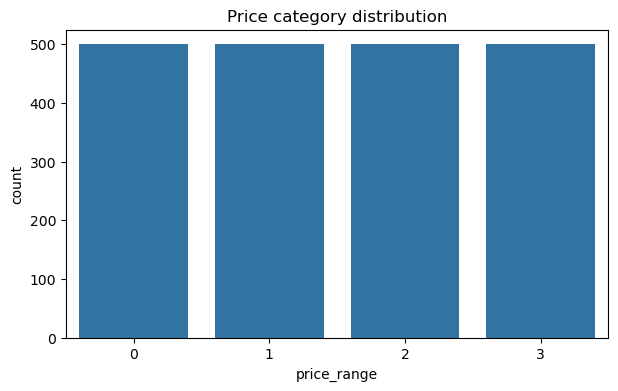

RAM correlation: 0.917


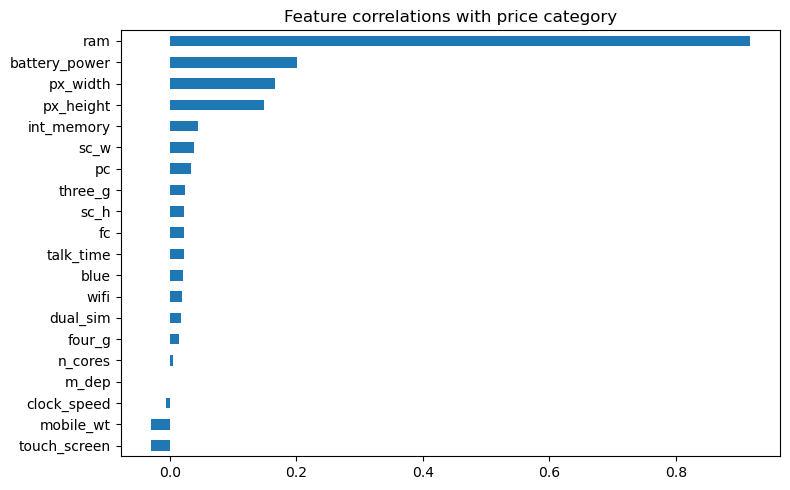

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="price_range", ax=ax)
ax.set_title("Price category distribution")
plt.show()

correlations = df.corr(numeric_only=True)["price_range"].drop("price_range").sort_values()
print("RAM correlation:", round(correlations["ram"], 3))
fig, ax = plt.subplots(figsize=(8, 5))
correlations.plot.barh(ax=ax)
ax.set_title("Feature correlations with price category")
plt.tight_layout()
plt.show()

## Split first, then tune
The original coursework notebook scaled the full dataset and selected K before splitting. This revised version avoids using test information during preprocessing and parameter selection. Scaling is inside a Pipeline, so it is fitted separately within each training fold.

In [4]:
X = df.drop(columns="price_range")
y = df["price_range"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    {"kneighborsclassifier__n_neighbors": list(range(1, 31))},
    cv=cv, scoring="accuracy", n_jobs=-1
)
search.fit(X_train, y_train)
knn = search.best_estimator_
print("Best K on training folds:", search.best_params_["kneighborsclassifier__n_neighbors"])

Best K on training folds: 26


In [5]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)
models = {"KNN": knn, "Decision Tree": tree}
rows = []
for name, model in models.items():
    cv_accuracy = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy").mean()
    test_accuracy = accuracy_score(y_test, model.predict(X_test))
    rows.append({"Model": name, "Training CV accuracy": cv_accuracy, "Test accuracy": test_accuracy})
results = pd.DataFrame(rows)
display(results)

,Model,Training CV accuracy,Test accuracy
0,KNN,0.593750,0.6375
1,Decision Tree,0.815625,0.8300


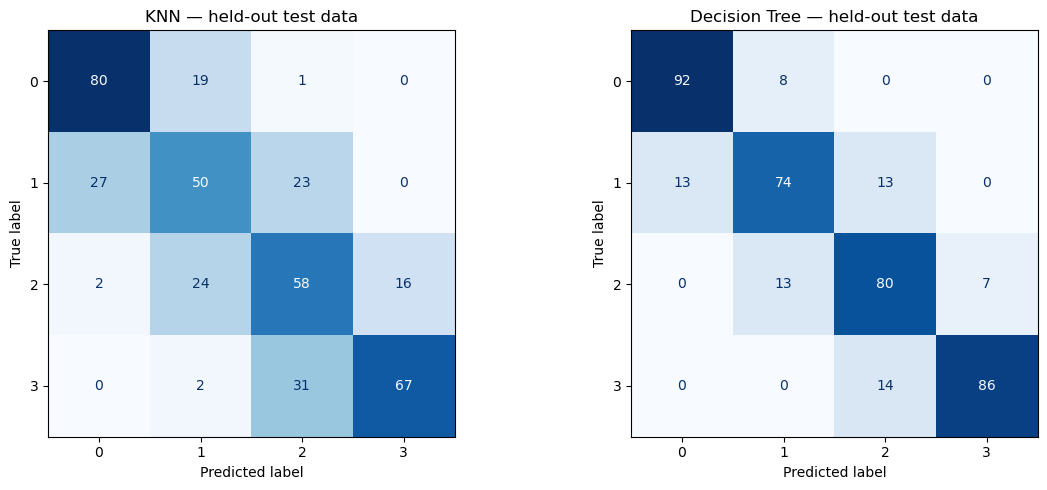

Decision Tree classification report:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90       100
           1       0.78      0.74      0.76       100
           2       0.75      0.80      0.77       100
           3       0.92      0.86      0.89       100

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400



In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name + " — held-out test data")
plt.tight_layout()
plt.show()

print("Decision Tree classification report:")
print(classification_report(y_test, tree.predict(X_test)))

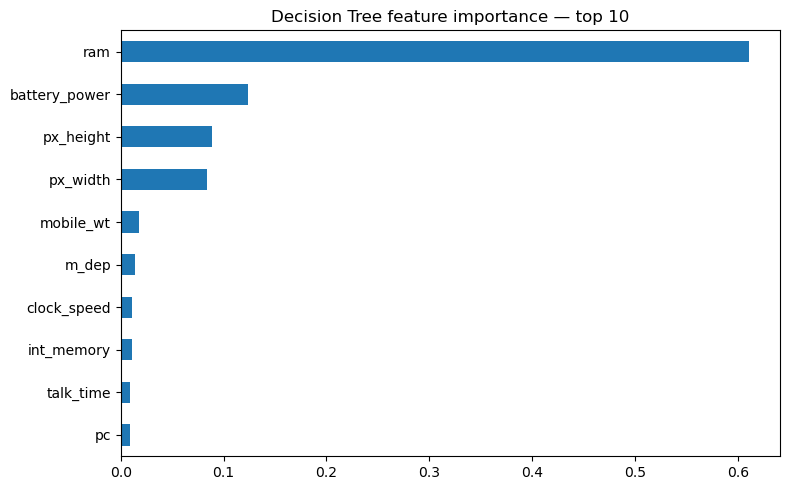

In [7]:
importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values().tail(10)
importance.plot.barh(figsize=(8, 5), title="Decision Tree feature importance — top 10")
plt.tight_layout()
plt.show()